In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("المجلد الحالي:", os.getcwd())

df = pd.read_csv("data/raw/telco_churn.csv")
df.columns = df.columns.str.strip()
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(0)

print("الأبعاد:", df.shape)
print("قيم فارغة:", df["TotalCharges"].isnull().sum())
print("✅ df جاهز")

المجلد الحالي: C:\Users\7mood\telco-churn-prediction
الأبعاد: (7043, 21)
قيم فارغة: 0
✅ df جاهز


In [2]:
import pandas as pd
print("البيئة تعمل ✅")
print("إصدار pandas:", pd.__version__)

البيئة تعمل ✅
إصدار pandas: 3.0.3


In [3]:
import pandas as pd

df = pd.read_csv("data/raw/telco_churn.csv")
print("الأبعاد:", df.shape)

الأبعاد: (7043, 21)


In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [6]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [7]:
print("عدد الأعمدة:", df.shape[1])
print(df.columns.tolist())
df.head(3)

عدد الأعمدة: 21
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


In [8]:
print(df.columns.tolist())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [9]:
print("عدد الأعمدة:", len(df.columns))
print("عدد الصفوف:", len(df))

عدد الأعمدة: 21
عدد الصفوف: 7043


In [10]:
for i, col in enumerate(df.columns, 1):
    print(i, col)

1 customerID
2 gender
3 SeniorCitizen
4 Partner
5 Dependents
6 tenure
7 PhoneService
8 MultipleLines
9 InternetService
10 OnlineSecurity
11 OnlineBackup
12 DeviceProtection
13 TechSupport
14 StreamingTV
15 StreamingMovies
16 Contract
17 PaperlessBilling
18 PaymentMethod
19 MonthlyCharges
20 TotalCharges
21 Churn


In [11]:
with open("data/raw/telco_churn.csv", "r", encoding="utf-8") as f:
    print(f.readline())

customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn



In [12]:
import pandas as pd

df = pd.read_csv("data/raw/telco_churn.csv")

print("الأبعاد:", df.shape)
print("عدد الأعمدة:", len(df.columns))
print("عمود Churn موجود؟", "Churn" in df.columns)
print("آخر 5 أعمدة:", df.columns[-5:].tolist())

الأبعاد: (7043, 21)
عدد الأعمدة: 21
عمود Churn موجود؟ True
آخر 5 أعمدة: ['PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [13]:
df.columns = df.columns.str.strip()   # يحذف أي مسافات مخفية من أسماء الأعمدة

In [14]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [15]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [16]:
df["Churn"].value_counts(normalize=True)

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

In [17]:
print(df["TotalCharges"].dtype)
print(df["MonthlyCharges"].dtype)

str
float64


In [18]:
print(df["TotalCharges"].isnull().sum())

0


In [19]:
df["TotalCharges"].str.strip().eq("").sum()

np.int64(11)

In [20]:
mask = df["TotalCharges"].str.strip() == ""
df.loc[mask, ["tenure", "MonthlyCharges", "TotalCharges"]]

,tenure,MonthlyCharges,TotalCharges
488,0,52.55,
753,0,20.25,
936,0,80.85,
1082,0,25.75,
1340,0,56.05,
3331,0,19.85,
3826,0,25.35,
4380,0,20.00,
5218,0,19.70,
6670,0,73.35,


In [21]:
mask = df["TotalCharges"].str.strip() == ""
print(df.loc[mask, "tenure"].unique())

[0]


In [22]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("النوع الآن:", df["TotalCharges"].dtype)
print("قيم فارغة:", df["TotalCharges"].isnull().sum())

النوع الآن: float64
قيم فارغة: 11


### تنظيف TotalCharges

**المشكلة:** العمود مخزّن كنصّ رغم أنه مبلغ مالي.

**السبب:** 11 قيمة تحتوي مسافة فارغة `" "` بدل رقم.

**التحقيق:** جميع هؤلاء العملاء لديهم `tenure = 0` — أي اشتركوا للتوّ ولم تصدر لهم فاتورة.

**القرار:** التحويل إلى رقم، ثم تعبئة الفراغات بـ **صفر** — لأنها القيمة الصحيحة واقعيًا (لم يدفعوا شيئًا).
لم نستخدم المتوسط (2279.73) لأنه كان سيزعم أن عميلًا عمره يوم دفع آلاف الريالات.

In [23]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)
print("قيم فارغة:", df["TotalCharges"].isnull().sum())
print("متوسط الإجمالي:", df["TotalCharges"].mean().round(2))

قيم فارغة: 0
متوسط الإجمالي: 2279.73


In [24]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [25]:
df["Churn"].value_counts(normalize=True).round(3)

Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64

### فرضياتي قبل التحليل

1. **العقد الشهري يزيد الانصراف** — لأنه بلا غرامة، فالخروج سهل.
2. **كلما طال tenure قلّ الانصراف** — لأن العميل القديم مرتبط، والترك أصعب عليه.
3. **الفاتورة المرتفعة تزيد الانصراف** — لأنها تدفع العميل للبحث عن بديل أرخص.

سؤال حاسم: هل العقد الشهري يسبّب الانصراف؟
أم أن العملاء المتردّدين أصلًا هم من يختارون العقد الشهري لأنهم لا يريدون الالتزام؟
لا تستطيع البيانات أن تجيب. الأرقام تُظهر ارتباطًا (Correlation)، لا سببية (Causation).
اكتب هذا في دفترك. المُحاور الجيد سيسألك عنه، والمرشّح الضعيف سيقول "العقد الشهري يسبّب الانصراف" بثقة خاطئة.

In [26]:
df.groupby("Contract")["Churn"].value_counts(normalize=True).round(3)

Contract        Churn
Month-to-month  No       0.573
                Yes      0.427
One year        No       0.887
                Yes      0.113
Two year        No       0.972
                Yes      0.028
Name: proportion, dtype: float64

In [27]:
df.groupby("Churn")["tenure"].mean().round(1)

Churn
No     37.6
Yes    18.0
Name: tenure, dtype: float64

In [28]:
df.groupby("Churn")["tenure"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,37.6,24.1,0.0,15.0,38.0,61.0,72.0
Yes,1869.0,18.0,19.5,1.0,2.0,10.0,29.0,72.0


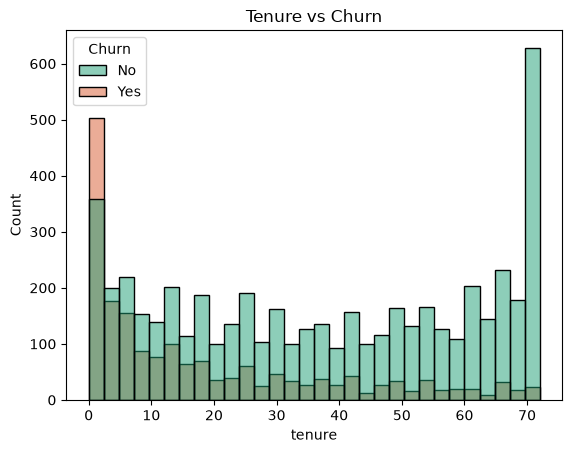

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(data=df, x="tenure", hue="Churn", bins=30, palette=["#1D9E75", "#D85A30"])
plt.title("Tenure vs Churn")
plt.show()

In [30]:
df.groupby("Churn")["MonthlyCharges"].mean().round(2)

Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64

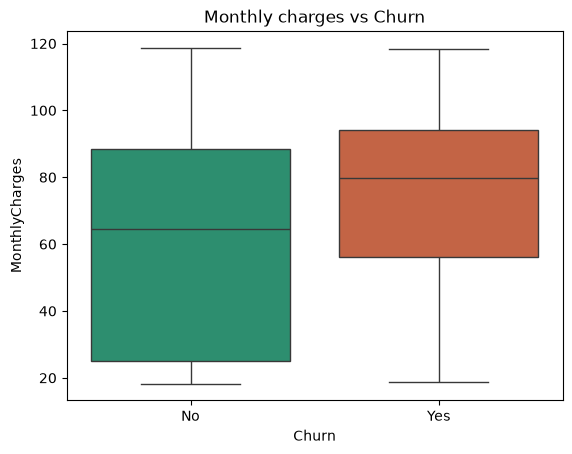

In [31]:
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", hue="Churn", 
            palette=["#1D9E75", "#D85A30"], legend=False)
plt.title("Monthly charges vs Churn")
plt.show()

In [32]:
df.groupby("InternetService")["MonthlyCharges"].mean().round(2)

InternetService
DSL            58.10
Fiber optic    91.50
No             21.08
Name: MonthlyCharges, dtype: float64

In [33]:
df.groupby("InternetService")["Churn"].value_counts(normalize=True).round(3)

InternetService  Churn
DSL              No       0.810
                 Yes      0.190
Fiber optic      No       0.581
                 Yes      0.419
No               No       0.926
                 Yes      0.074
Name: proportion, dtype: float64

In [34]:
fiber = df[df["InternetService"] == "Fiber optic"]
fiber.groupby("Churn")["MonthlyCharges"].mean().round(2)

Churn
No     93.93
Yes    88.13
Name: MonthlyCharges, dtype: float64

### مفارقة سيمبسون في بياناتنا

**ملاحظة أولية:** المنصرفون يدفعون أكثر (74.44 مقابل 61.27) → بدا أن السعر يطرد العملاء.

**بعد التحكّم في نوع الإنترنت:** داخل الألياف وحدها، المنصرفون يدفعون **أقلّ** (88.13 مقابل 93.93).

**الاستنتاج:** الفاتورة ليست سببًا. `InternetService` متغيّر مُربِك — الألياف غالية وعالية الانصراف معًا.

**التوصية المصحَّحة:** ❌ لا تخفضوا الأسعار.
✅ حقّقوا في **جودة خدمة الألياف** (41.9% انصراف!).
✅ افحصوا: هل الخدمات الإضافية (أمان، دعم) هي ما يُبقي دافعي 94 ريالًا؟

**النتيجة 3 — مفاجأة كذّبت فرضيتي:**
توقّعتُ أن مشتركي الألياف (الخدمة الأفضل) سيبقون. الحقيقة عكس ذلك:
- الألياف: 41.9% انصراف | DSL: 19.0% | بلا إنترنت: 7.4%
- الألياف أغلى (91.50) وأكثر انصرافًا معًا.

**التفسير:** `InternetService` متغيّر مُربِك (Confounder). الفاتورة المرتفعة للمنصرفين
ليست سببًا مستقلًّا — بل انعكاس لتركّزهم في خدمة الألياف الغالية.

**الرؤية:** السعر الأعلى يرفع سقف التوقّعات، فيقلّ الاحتمال في الصبر على أي خلل.

**التوصية:** تحقيق في جودة خدمة الألياف — هل المشكلة تقنية أم تسعيرية؟

In [35]:
fiber.groupby("OnlineSecurity")["Churn"].value_counts(normalize=True).round(3)

OnlineSecurity  Churn
No              No       0.506
                Yes      0.494
Yes             No       0.782
                Yes      0.218
Name: proportion, dtype: float64

In [36]:
fiber.groupby("TechSupport")["Churn"].value_counts(normalize=True).round(3)

TechSupport  Churn
No           No       0.506
             Yes      0.494
Yes          No       0.774
             Yes      0.226
Name: proportion, dtype: float64

### حلّ اللغز: الفاتورة أثر لا سبب

**داخل مشتركي الألياف:**
| الخدمة | بلا الخدمة | مع الخدمة |
|---|---|---|
| OnlineSecurity | 49.4% | 21.8% |
| TechSupport | 49.4% | 22.6% |

**الاستنتاج:** الخدمات الإضافية ترفع الفاتورة **وتخفض الانصراف** إلى النصف.
لذلك بدا المنصرفون "أرخص" داخل الألياف — لأنهم ببساطة لم يشتروا ما يربطهم.

**التوصية:** تضمين الأمان والدعم في باقة الألياف، أو تقديمهما مجانًا.
العائد: خفض متوقّع للانصراف من ~49% إلى ~22% لهذه الشريحة.

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/raw/telco_churn.csv")
df.columns = df.columns.str.strip()
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(0)

print("الأبعاد:", df.shape)
print("نوع TotalCharges:", df["TotalCharges"].dtype)
print("قيم فارغة:", df["TotalCharges"].isnull().sum())

الأبعاد: (7043, 21)
نوع TotalCharges: float64
قيم فارغة: 0


In [38]:
y = (df["Churn"] == "Yes").astype(int)
X = df.drop(columns=["Churn", "customerID"])
X = pd.get_dummies(X, drop_first=True)

print("عدد الميزات:", X.shape[1])
print("نسبة المنصرفين:", y.mean().round(3))

عدد الميزات: 30
نسبة المنصرفين: 0.265


In [39]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("تدريب:", X_train.shape[0], "عميلًا")
print("اختبار:", X_test.shape[0], "عميلًا")
print("نسبة المنصرفين — تدريب:", y_train.mean().round(3))
print("نسبة المنصرفين — اختبار:", y_test.mean().round(3))

تدريب: 5634 عميلًا
اختبار: 1409 عميلًا
نسبة المنصرفين — تدريب: 0.265
نسبة المنصرفين — اختبار: 0.265


In [40]:
from sklearn.preprocessing import StandardScaler

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
scaler = StandardScaler()

X_train_s = X_train.copy()
X_test_s = X_test.copy()

X_train_s[num_cols] = scaler.fit_transform(X_train[num_cols])   # fit + transform
X_test_s[num_cols]  = scaler.transform(X_test[num_cols])        # transform فقط

print("متوسط tenure بعد القياس (تدريب):", X_train_s["tenure"].mean().round(3))
print("✅ القياس تمّ بلا تسرّب")

متوسط tenure بعد القياس (تدريب): -0.0
✅ القياس تمّ بلا تسرّب


In [41]:
naive_accuracy = (y_test == 0).mean()
print(f"دقة النموذج الساذج: {naive_accuracy:.1%}")
print("(نموذج يقول: كل عميل سيبقى)")

دقة النموذج الساذج: 73.5%
(نموذج يقول: كل عميل سيبقى)


In [42]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=2000)
model.fit(X_train_s, y_train)          # التعلّم — من التدريب فقط

y_pred = model.predict(X_test_s)       # التنبؤ — الآن نفتح الدرج

print("✅ النموذج تدرّب وتنبّأ")

✅ النموذج تدرّب وتنبّأ


In [43]:
from sklearn.metrics import accuracy_score

acc = accuracy_score(y_test, y_pred)
print(f"دقة النموذج:  {acc:.1%}")
print(f"دقة الساذج:   73.5%")
print(f"التحسّن:      {(acc - 0.735)*100:.1f} نقطة")

دقة النموذج:  80.6%
دقة الساذج:   73.5%
التحسّن:      7.1 نقطة


In [44]:
from sklearn.metrics import confusion_matrix, classification_report

cm = confusion_matrix(y_test, y_pred)
print(cm)

[[927 108]
 [165 209]]


In [45]:
print(classification_report(y_test, y_pred, target_names=["سيبقى", "سينصرف"]))

              precision    recall  f1-score   support

       سيبقى       0.85      0.90      0.87      1035
      سينصرف       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [46]:
model_balanced = LogisticRegression(max_iter=2000, class_weight="balanced")
model_balanced.fit(X_train_s, y_train)
y_pred_bal = model_balanced.predict(X_test_s)

print(classification_report(y_test, y_pred_bal, target_names=["سيبقى", "سينصرف"]))

              precision    recall  f1-score   support

       سيبقى       0.90      0.72      0.80      1035
      سينصرف       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



## المرحلة 8 — تحسين النموذج

نبني Random Forest كمنافس للانحدار اللوجستي، ثم نتحقق من ثباته بـ Cross-Validation، ونضبط مُعاملاته بـ GridSearchCV، وأخيرًا نضبط حد التصنيف بدل الاكتفاء بالحد الافتراضي 0.5.

In [47]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=200, random_state=42)
rf_model.fit(X_train_s, y_train)
y_pred_rf = rf_model.predict(X_test_s)

print(classification_report(y_test, y_pred_rf, target_names=["سيبقى", "سينصرف"]))

              precision    recall  f1-score   support

       سيبقى       0.83      0.89      0.86      1035
      سينصرف       0.63      0.51      0.56       374

    accuracy                           0.79      1409
   macro avg       0.73      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409



In [48]:
rf_balanced = RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42)
rf_balanced.fit(X_train_s, y_train)
y_pred_rf_bal = rf_balanced.predict(X_test_s)

print(classification_report(y_test, y_pred_rf_bal, target_names=["سيبقى", "سينصرف"]))

              precision    recall  f1-score   support

       سيبقى       0.86      0.82      0.84      1035
      سينصرف       0.57      0.64      0.60       374

    accuracy                           0.78      1409
   macro avg       0.72      0.73      0.72      1409
weighted avg       0.79      0.78      0.78      1409



### Cross-Validation

نتيجة اختبار واحدة (X_test) قد تكون محظوظة أو سيئة الحظ بالصدفة. نتحقق من ثبات كل نموذج بتقسيم بيانات **التدريب فقط** إلى 5 طيّات (StratifiedKFold) وقياس المتوسط والانحراف المعياري لمقياس Recall على فئة الانصراف.

In [49]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

candidates = {
    "Logistic (balanced)": model_balanced,
    "Random Forest": rf_model,
    "Random Forest (balanced)": rf_balanced,
}

for name, clf in candidates.items():
    scores = cross_val_score(clf, X_train_s, y_train, cv=cv, scoring="recall")
    print(f"{name:28s}  recall = {scores.mean():.3f} ± {scores.std():.3f}")

Logistic (balanced)           recall = 0.802 ± 0.038


Random Forest                 recall = 0.472 ± 0.024


Random Forest (balanced)      recall = 0.647 ± 0.031


### ضبط المُعاملات (GridSearchCV)

نبحث عن أفضل مُعاملات لـ Random Forest المتوازن، بالتحسين على Recall عبر Cross-Validation على بيانات التدريب فقط — لا لمس لبيانات الاختبار أثناء البحث، تجنّبًا للتسرّب.

In [50]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [200, 400],
    "max_depth": [5, 10, None],
    "min_samples_leaf": [1, 5, 10],
}

grid = GridSearchCV(
    RandomForestClassifier(class_weight="balanced", random_state=42),
    param_grid=param_grid,
    scoring="recall",
    cv=cv,
    n_jobs=-1,
)
grid.fit(X_train_s, y_train)

print("أفضل مُعاملات:", grid.best_params_)
print(f"أفضل recall (تدريب، CV): {grid.best_score_:.3f}")

best_rf = grid.best_estimator_
y_pred_best = best_rf.predict(X_test_s)
print()
print(classification_report(y_test, y_pred_best, target_names=["سيبقى", "سينصرف"]))

أفضل مُعاملات: {'max_depth': 5, 'min_samples_leaf': 10, 'n_estimators': 200}
أفضل recall (تدريب، CV): 0.823

              precision    recall  f1-score   support

       سيبقى       0.92      0.70      0.79      1035
      سينصرف       0.50      0.83      0.62       374

    accuracy                           0.73      1409
   macro avg       0.71      0.77      0.71      1409
weighted avg       0.81      0.73      0.75      1409



In [51]:
from sklearn.metrics import recall_score

train_recall = recall_score(y_train, best_rf.predict(X_train_s))
test_recall = recall_score(y_test, y_pred_best)

print(f"Recall على التدريب: {train_recall:.3f}")
print(f"Recall على الاختبار: {test_recall:.3f}")
print(f"الفجوة: {train_recall - test_recall:.3f}  (فجوة كبيرة = Overfitting)")

Recall على التدريب: 0.846
Recall على الاختبار: 0.832
الفجوة: 0.015  (فجوة كبيرة = Overfitting)


### ضبط حد التصنيف (Threshold Tuning)

`predict()` تستخدم حد 0.5 افتراضيًا. لكن قرار العمل هنا ليس متماثلًا: تفويت عميل سينصرف فعلًا (False Negative) أغلى من التواصل خطأً مع عميل لن ينصرف (False Positive). نفحص طيف الحدود من 0.1 إلى 0.9 على احتمالات `best_rf`، ونرصد كيف تتحرك Precision وRecall وF1 معًا.

In [52]:
from sklearn.metrics import precision_score, f1_score

y_proba = best_rf.predict_proba(X_test_s)[:, 1]

thresholds = np.arange(0.1, 0.95, 0.05)
rows = []
for t in thresholds:
    preds = (y_proba >= t).astype(int)
    rows.append({
        "threshold": round(t, 2),
        "precision": round(precision_score(y_test, preds), 3),
        "recall": round(recall_score(y_test, preds), 3),
        "f1": round(f1_score(y_test, preds), 3),
    })

threshold_df = pd.DataFrame(rows)
threshold_df

C:\Users\7mood\telco-churn-prediction\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


,threshold,precision,recall,f1
0,0.10,0.307,0.997,0.469
1,0.15,0.331,0.992,0.496
2,0.20,0.348,0.987,0.515
3,0.25,0.372,0.963,0.536
4,0.30,0.398,0.936,0.559
5,0.35,0.415,0.914,0.570
6,0.40,0.442,0.890,0.590
7,0.45,0.462,0.866,0.603
8,0.50,0.499,0.832,0.624
9,0.55,0.538,0.751,0.627


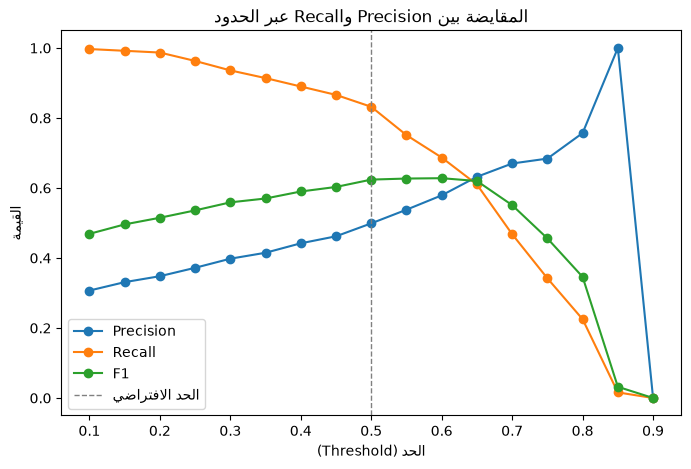

In [53]:
plt.figure(figsize=(8, 5))
plt.plot(threshold_df["threshold"], threshold_df["precision"], marker="o", label="Precision")
plt.plot(threshold_df["threshold"], threshold_df["recall"], marker="o", label="Recall")
plt.plot(threshold_df["threshold"], threshold_df["f1"], marker="o", label="F1")
plt.axvline(0.5, color="gray", linestyle="--", linewidth=1, label="الحد الافتراضي")
plt.xlabel("الحد (Threshold)")
plt.ylabel("القيمة")
plt.title("المقايضة بين Precision وRecall عبر الحدود")
plt.legend()
plt.show()

In [54]:
# قرار العمل: نريد اكتشاف 75% على الأقل من العملاء المعرّضين للانصراف (Recall >= 0.75)،
# وبين كل الحدود التي تحقق هذا، نختار الأعلى دقة (Precision) لتقليل التواصل غير الضروري.
eligible = threshold_df[threshold_df["recall"] >= 0.75]
chosen = eligible.sort_values("precision", ascending=False).iloc[0]

print("الحد المختار:", chosen["threshold"])
print(chosen)

final_preds = (y_proba >= chosen["threshold"]).astype(int)
print()
print(classification_report(y_test, final_preds, target_names=["سيبقى", "سينصرف"]))

الحد المختار: 0.55
threshold    0.550
precision    0.538
recall       0.751
f1           0.627
Name: 9, dtype: float64

              precision    recall  f1-score   support

       سيبقى       0.90      0.77      0.83      1035
      سينصرف       0.54      0.75      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.76      0.77      1409



## المرحلة 9 — التفسير وتوصيات العمل

النموذج جاهز، لكن الرقم وحده لا يقنع مديرًا. نستخرج أهمية الميزات من `best_rf` لنعرف أي العوامل قادت قراره فعليًا، ونربطها بما اكتشفناه في EDA.

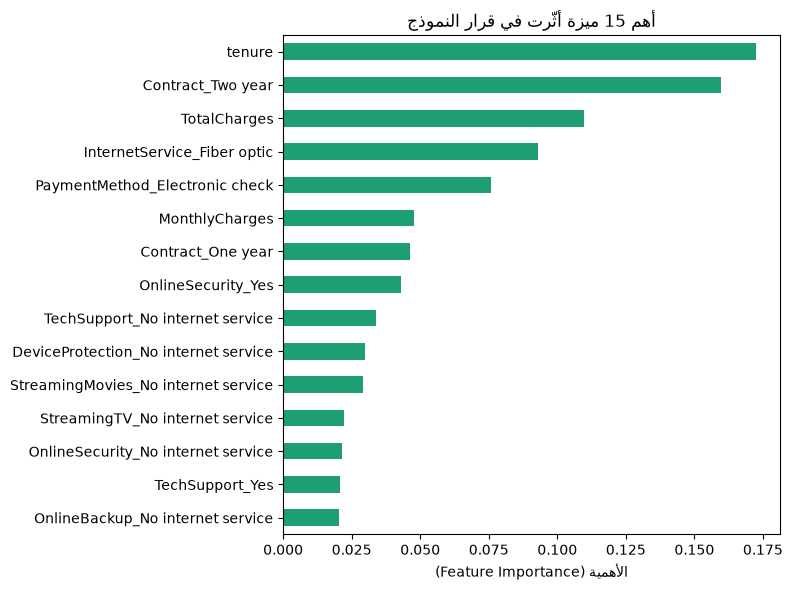

tenure                                  0.172598
Contract_Two year                       0.159864
TotalCharges                            0.109900
InternetService_Fiber optic             0.093097
PaymentMethod_Electronic check          0.075823
MonthlyCharges                          0.047658
Contract_One year                       0.046109
OnlineSecurity_Yes                      0.042919
TechSupport_No internet service         0.033961
DeviceProtection_No internet service    0.030021
StreamingMovies_No internet service     0.029123
StreamingTV_No internet service         0.022307
OnlineSecurity_No internet service      0.021396
TechSupport_Yes                         0.020739
OnlineBackup_No internet service        0.020338
dtype: float64

In [55]:
importances = pd.Series(best_rf.feature_importances_, index=X_train_s.columns)
top15 = importances.sort_values(ascending=False).head(15)

plt.figure(figsize=(8, 6))
top15.sort_values().plot(kind="barh", color="#1D9E75")
plt.title("أهم 15 ميزة أثّرت في قرار النموذج")
plt.xlabel("الأهمية (Feature Importance)")
plt.tight_layout()
plt.show()

top15

### التوصيات النهائية (مبنية على EDA + أهمية الميزات الفعلية)

أعلى 4 ميزات في `best_rf` فعليًا: `tenure` (0.173) → `Contract_Two year` (0.160) → `TotalCharges` (0.110) → `InternetService_Fiber optic` (0.093). هذا يتوافق تمامًا مع اكتشافات EDA:

1. **العملاء الجدد (tenure منخفض) هم الأعلى خطورة، وأهم ميزة في النموذج على الإطلاق.** أول 90 يومًا نافذة حرجة لبرنامج ولاء استباقي قبل أن يقرر العميل الرحيل.
2. **العقد طويل المدى أقوى حماية من الانصراف.** عقد السنتين وحده يخفّض الانصراف إلى 2.8% مقابل 42.7% للعقد الشهري — استهدفوا عملاء العقد الشهري بحوافز للتحويل لعقد أطول.
3. **حقّقوا في جودة خدمة الألياف الضوئية بدل خفض سعرها.** مشتركو الألياف الأعلى انصرافًا (41.9%)، لكن التحليل أثبت أن السبب الحقيقي غياب الخدمات الإضافية لا السعر نفسه (مفارقة سيمبسون في EDA).
4. **قدّموا `OnlineSecurity` و`TechSupport` كجزء من باقة الألياف أو مجانًا.** داخل مشتركي الألياف، وجود هاتين الخدمتين يخفّض الانصراف من ~49% إلى ~22%، وتظهران أيضًا ضمن أهم 15 ميزة.

**كيف تُستخدم توقعات النموذج عمليًا:** عند الحد المختار (0.55)، النموذج يكتشف 75.1% من العملاء المعرّضين فعليًا للانصراف بدقة 53.8% — القائمة الناتجة (`final_preds == 1`) هي من يستهدفهم فريق الاحتفاظ بالعملاء أولًا.

### جدول القرار — مقارنة كل النماذج

ملخص الرحلة من الـ baseline الساذج إلى النموذج النهائي، ولماذا اخترنا كل خطوة.

In [56]:
from sklearn.metrics import accuracy_score

naive_preds = np.zeros_like(y_test)

comparison_rows = [
    ("ساذج (الكل سيبقى)", naive_preds),
    ("انحدار لوجستي", y_pred),
    ("انحدار لوجستي (balanced)", y_pred_bal),
    ("Random Forest", y_pred_rf),
    ("Random Forest (balanced)", y_pred_rf_bal),
    ("Random Forest (مضبوط بـ GridSearch)", y_pred_best),
    (f"النموذج النهائي (حد {chosen['threshold']})", final_preds),
]

comparison_df = pd.DataFrame([
    {
        "النموذج": name,
        "Accuracy": round(accuracy_score(y_test, preds), 3),
        "Precision": round(precision_score(y_test, preds, zero_division=0), 3),
        "Recall": round(recall_score(y_test, preds), 3),
        "F1": round(f1_score(y_test, preds, zero_division=0), 3),
    }
    for name, preds in comparison_rows
])
comparison_df

,النموذج,Accuracy,Precision,Recall,F1
0,ساذج (الكل سيبقى),0.735,0.000,0.000,0.000
1,انحدار لوجستي,0.806,0.659,0.559,0.605
2,انحدار لوجستي (balanced),0.738,0.504,0.783,0.614
3,Random Forest,0.790,0.629,0.508,0.562
4,Random Forest (balanced),0.776,0.569,0.642,0.603
5,Random Forest (مضبوط بـ GridSearch),0.734,0.499,0.832,0.624
6,النموذج النهائي (حد 0.55),0.763,0.538,0.751,0.627


## المرحلة 10 — الخلاصة

المشروع مكتمل: تنظيف موثّق، EDA بفرضيات ونتائج، معالجة بلا تسرّب، Baseline، تحسين عبر Random Forest وCross-Validation وGridSearchCV، ضبط حد مبني على قرار عمل، أهمية ميزات، وتوصيات محددة. التفاصيل الكاملة والتشغيل المحلي موثّقة في `README.md`.